# Phase 1: openFDA device data, exploratory analysis

This notebook walks through the Phase 1 data: what we downloaded, whether it is complete, and what it looks like. Every number shown is read from `results/phase1/` (made by `python -m mdqc.eda`) and was recomputed independently by `python -m mdqc.verify_phase1`. The written findings are in [`docs/EDA_FINDINGS.md`](../docs/EDA_FINDINGS.md).

**Key ideas**
- **MAUDE report (MDR):** a manufacturer, hospital or patient tells the FDA a device *may* have been involved in a death, injury or malfunction. It is a signal, not a confirmed failure.
- **Product code:** FDA's 3-letter device category. Our scope (pre-registered in `config/scope.json`): LPH hip, JWH and MBH knees, LWP pacemaker, LZG insulin pump; reports received 2022-2024.
- **No denominator:** we never know how many devices are in use, so counts are not failure rates.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
S = json.loads((ROOT / 'results/phase1/eda_summary.json').read_text(encoding='utf-8'))
M = json.loads((ROOT / 'results/phase1/download_manifest.json').read_text(encoding='utf-8'))
V = json.loads((ROOT / 'results/phase1/verify_phase1.json').read_text(encoding='utf-8'))
codes, pc = S['codes'], S['per_code']

## 1. Is the download complete?

Before each product code was downloaded we asked the server how many reports match; afterwards we counted what we got. Equal numbers and zero duplicates mean nothing was lost or doubled while paging through results 999 at a time.

In [2]:
pd.DataFrame({c: {'server total': e['server_total_before'], 'downloaded': e['downloaded'],
                  'duplicates': e['duplicates']} for c, e in M['events'].items()}).T

,server total,downloaded,duplicates
LPH,16196,16196,0
JWH,28138,28138,0
MBH,4021,4021,0
LWP,37414,37414,0
LZG,68425,68425,0


In [3]:
pd.DataFrame([(c['id'], c['check'], 'pass' if c['pass'] else 'FAIL') for c in V['checks']],
             columns=['id', 'check', 'result'])

,id,check,result
0,C1,event counts = server totals at download,pass
1,C2,recall counts = server totals,pass
2,C4,no duplicate report keys within a code,pass
3,C5,checksums match,pass
4,C3,every report in window and lists its code,pass
5,C6,independent recount of every summary number,pass
6,C7,no data or secrets in git; contact fields counted,pass
7,info,server totals today (openFDA keeps adding late...,pass
8,C8,published numbers = openFDA's own server-side ...,pass


## 2. Volume over time (Q1)

Each code has its own y-axis because volumes differ by 17x.

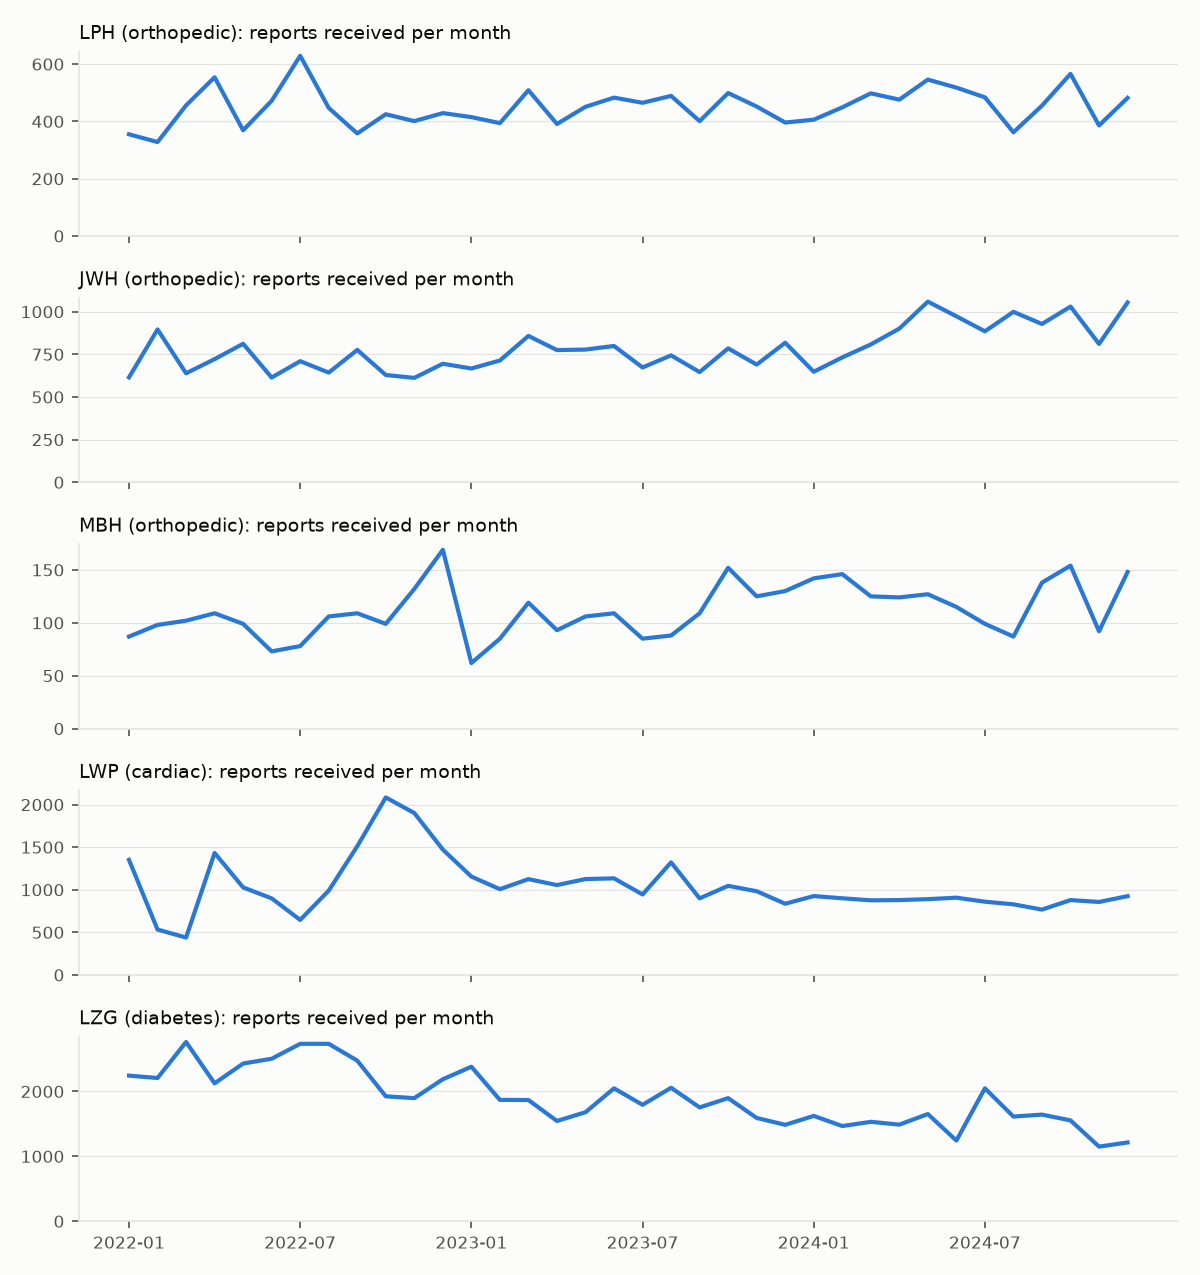

,reports,median / month,busiest month,busiest count
LPH,16196,451.5,2022-07,629
JWH,28138,775.5,2024-05,1059
MBH,4021,109.0,2022-12,169
LWP,37414,935.5,2022-10,2084
LZG,68425,1869.0,2022-03,2762


In [4]:
display(Image(filename=str(ROOT / 'docs/figures/phase1/monthly_reports.png'), width=800))
pd.DataFrame({c: {'reports': pc[c]['reports'], 'median / month': pc[c]['q1_monthly_median'],
                  'busiest month': pc[c]['q1_monthly_max_month'], 'busiest count': pc[c]['q1_monthly_max']}
              for c in codes}).T

## 3. What kind of events (Q2) and which problem terms (Q3)

Problem terms are counted once per report (openFDA repeats terms inside a report; see the correction in the findings doc).

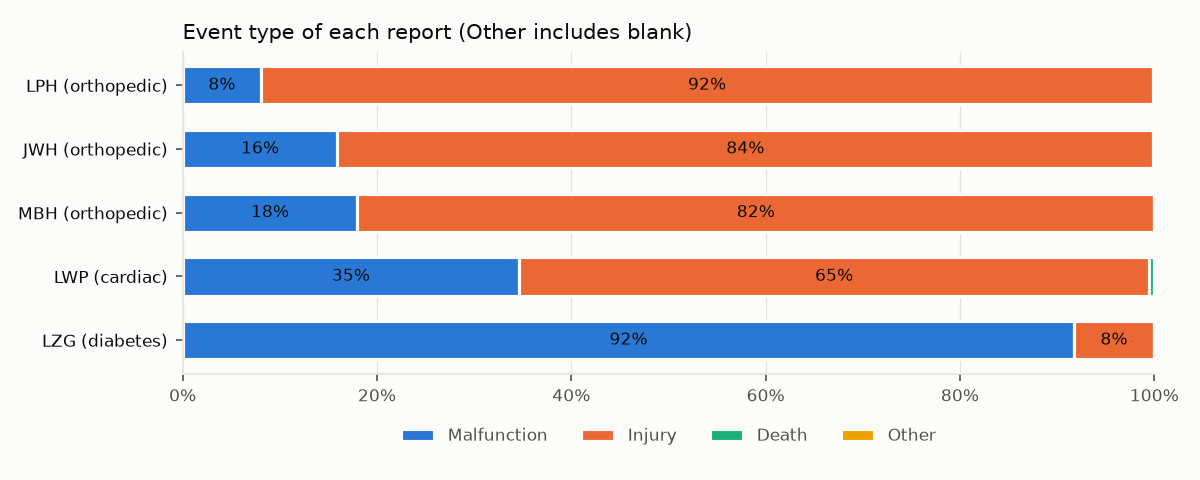

,Injury,Malfunction,Death,Other
LPH,14865,1309,21,1
JWH,23626,4482,21,9
MBH,3298,723,0,0
LWP,24249,12960,200,5
LZG,5574,62799,51,1


In [5]:
display(Image(filename=str(ROOT / 'docs/figures/phase1/event_type_mix.png'), width=800))
pd.DataFrame({c: pc[c]['q2_event_type'] for c in codes}).fillna(0).astype(int).T

In [6]:
pd.DataFrame({c: [f'{p} ({k:,})' for p, k in pc[c]['q3_top_problems'][:5]] for c in codes},
             index=[f'#{i}' for i in range(1, 6)])

,LPH,JWH,MBH,LWP,LZG
#1,Adverse Event Without Identified Device or Use...,Adverse Event Without Identified Device or Use...,Adverse Event Without Identified Device or Use...,Adverse Event Without Identified Device or Use...,"Unintended Movement (17,673)"
#2,"Device Dislodged or Dislocated (3,099)","Naturally Worn (4,852)",Fracture (578),"Premature Discharge of Battery (6,658)","Loss of or Failure to Bond (15,025)"
#3,Naturally Worn (942),"Fracture (3,420)",Unstable (402),"Over-Sensing (3,747)","Material Twisted/Bent (10,738)"
#4,Fracture (861),Loosening of Implant Not Related to Bone-Ingro...,Insufficient Device Problem Information (162),"Incorrect, Inadequate or Imprecise Result or R...","Failure to Fire (7,009)"
#5,Osseointegration Problem (671),"Unstable (1,732)",Loss of Osseointegration (162),"Battery Problem (2,784)","Insufficient Device Problem Information (4,777)"


The most common term for four of the five codes says no device problem was identified. The real failure description lives in the narrative text, which is why Phase 3 works from the text.

## 4. Manufacturers (Q4) and narratives (Q5)

In [7]:
pd.DataFrame({c: {'largest maker': pc[c]['q4_top_manufacturers'][0][0],
                  'its share': f"{pc[c]['q4_top_manufacturer_share']:.0%}",
                  'makers': pc[c]['q4_distinct_manufacturers'],
                  'with narrative': f"{pc[c]['q5_share_with_narrative']:.0%}",
                  'median narrative chars': pc[c]['q5_narrative_len_median']} for c in codes}).T

,largest maker,its share,makers,with narrative,median narrative chars
LPH,DEPUY ORTHOPAEDICS INC US,54%,82,100%,1724.0
JWH,"EXACTECH, INC.",23%,118,100%,1710.0
MBH,STRYKER ORTHOPAEDICS-MAHWAH,47%,31,100%,1493.0
LWP,BOSTON SCIENTIFIC CORPORATION,58%,52,100%,997.0
LZG,INSULET CORPORATION,74%,27,100%,791.0


## 5. Recalls (Q6), reporting lag (Q7), multi-device reports (Q8)

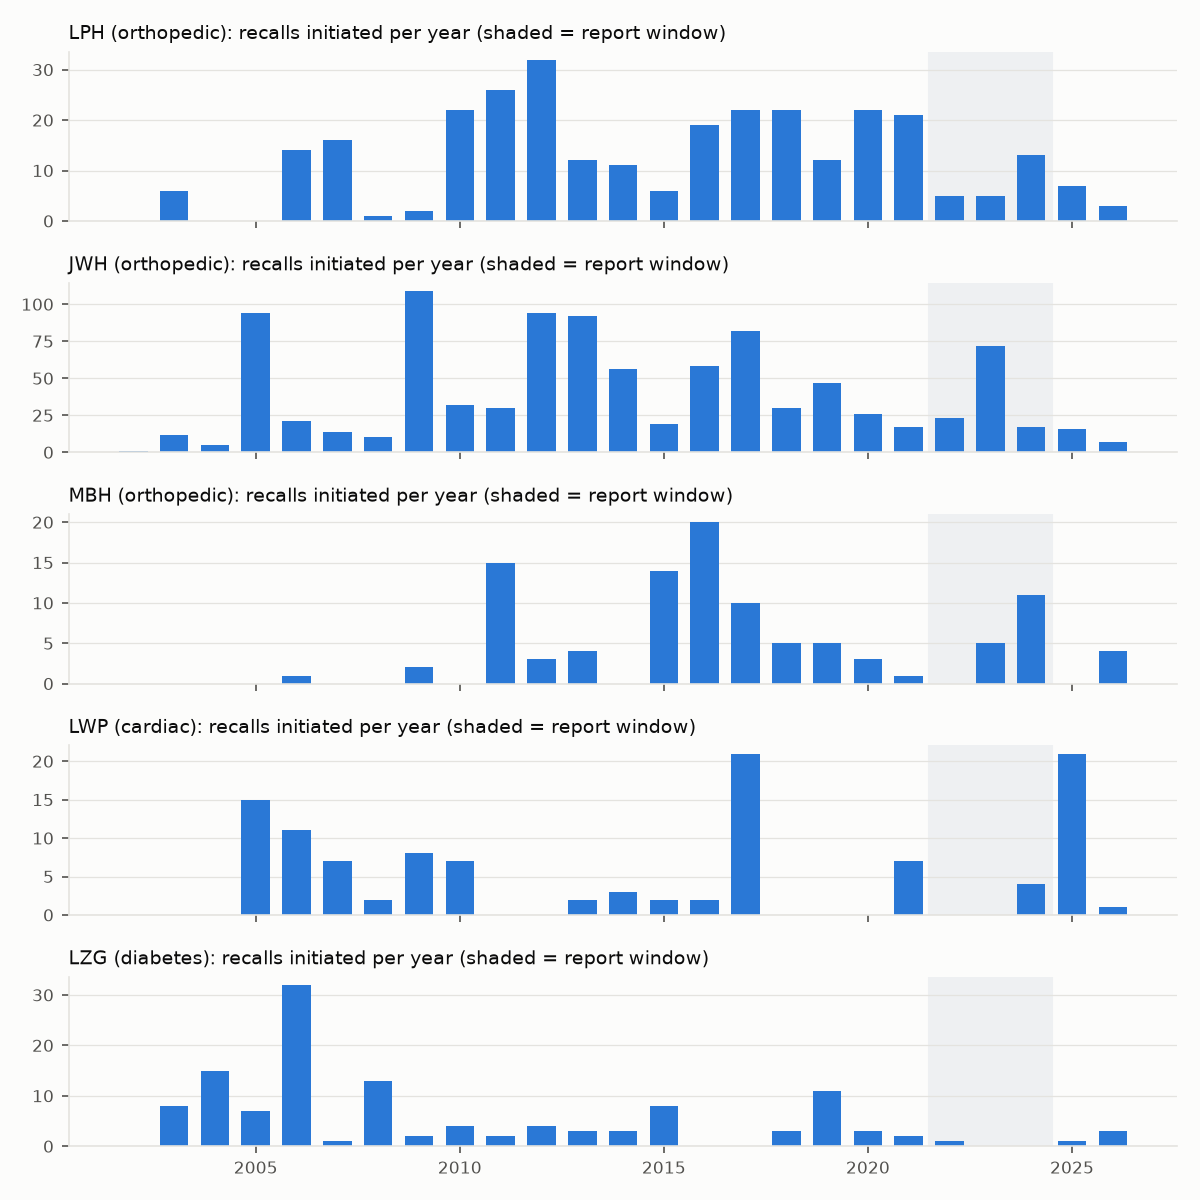

,recall records,recall events,in 2022-2024,invalid date,median lag (days),p90 lag (days),multi-device reports
LPH,299.0,105.0,23.0,0.0,22.0,573.4,203.0
JWH,985.0,288.0,112.0,1.0,26.0,868.0,115.0
MBH,103.0,44.0,16.0,0.0,24.0,403.8,68.0
LWP,113.0,30.0,4.0,0.0,21.0,99.0,53.0
LZG,126.0,58.0,1.0,0.0,12.0,45.0,29.0


In [8]:
display(Image(filename=str(ROOT / 'docs/figures/phase1/recalls_per_year.png'), width=800))
pd.DataFrame({c: {'recall records': pc[c]['q6_recalls'], 'recall events': pc[c]['q6_recall_events_distinct'],
                  'in 2022-2024': pc[c]['q6_recalls_in_window'],
                  'invalid date': pc[c]['q6_recalls_invalid_initiation_date'],
                  'median lag (days)': pc[c]['q7_lag_median_days'], 'p90 lag (days)': pc[c]['q7_lag_p90_days'],
                  'multi-device reports': pc[c]['q8_multi_device_reports']} for c in codes}).T

## 6. Manufacturer trends (Q9, added post hoc on the re-check)

A code's total can stay flat while one maker rises and another falls, so we also look at the three largest manufacturers per code. Names are as reported (St. Jude Medical is part of Abbott since 2017; Phase 2 merges such names).

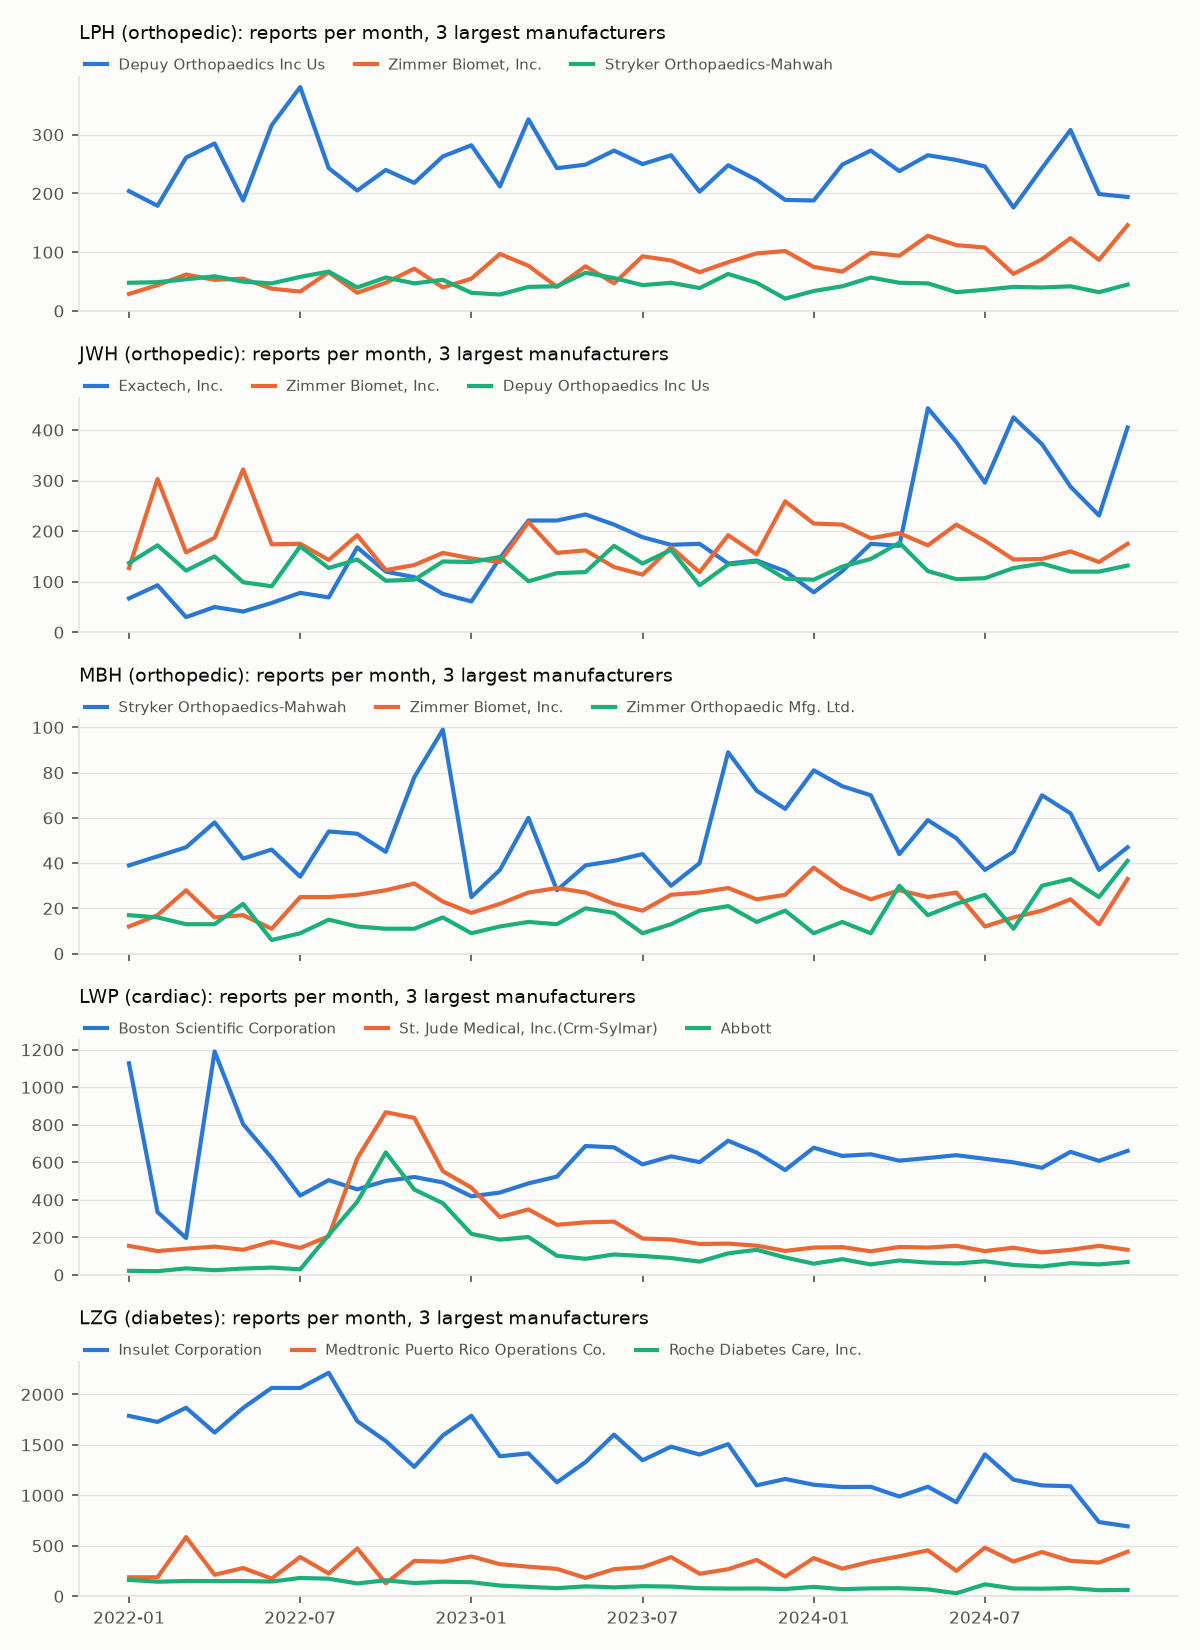

,code,manufacturer,2022,2023,2024
0,LPH,DEPUY ORTHOPAEDICS INC US,2983,2963,2836
1,LPH,"ZIMMER BIOMET, INC.",571,921,1191
2,LPH,STRYKER ORTHOPAEDICS-MAHWAH,629,526,496
3,JWH,"EXACTECH, INC.",959,2031,3382
4,JWH,"ZIMMER BIOMET, INC.",2194,1957,2139
5,JWH,DEPUY ORTHOPAEDICS INC US,1558,1568,1524
6,MBH,STRYKER ORTHOPAEDICS-MAHWAH,638,569,677
7,MBH,"ZIMMER BIOMET, INC.",259,296,288
8,MBH,ZIMMER ORTHOPAEDIC MFG. LTD.,161,181,267
9,LWP,BOSTON SCIENTIFIC CORPORATION,7178,6985,7540


In [9]:
display(Image(filename=str(ROOT / 'docs/figures/phase1/manufacturer_trends.png'), width=800))
pd.DataFrame([{'code': c, 'manufacturer': m, **by} for c in codes
              for m, by in pc[c]['q9_top3_by_year'].items()])

## 7. Findings

The findings text is generated from the same results files:

In [10]:
doc = (ROOT / 'docs/EDA_FINDINGS.md').read_text(encoding='utf-8')
display(Markdown(doc.split('## What stands out')[1].split('## Checks (criteria')[0]))



1. **Implants and pumps report differently.** Implant reports are mostly classed as injuries (LPH 92%, JWH 84%, MBH 82%, LWP 65%), because an implant problem that leads to another operation is reported as an injury; insulin pump reports are mostly malfunctions (LZG 92%). Raw counts must not be compared across device families.
2. **FDA problem codes are coarse.** The top term for 4 of 5 codes is "Adverse Event Without Identified Device or Use Problem" (LPH 48% of reports, JWH 42% of reports, MBH 47% of reports, LWP 32% of reports). The failure mode is in the narrative text, which every report has (median length LPH 1,724, JWH 1,710, MBH 1,493, LWP 997, LZG 791 characters). So Phase 3 groups failure modes from the text, with the FDA codes only as a weak baseline.
3. **One manufacturer often dominates a code.** Largest share: LPH DEPUY ORTHOPAEDICS INC US 54%; JWH EXACTECH, INC. 23%; MBH STRYKER ORTHOPAEDICS-MAHWAH 47%; LWP BOSTON SCIENTIFIC CORPORATION 58%; LZG INSULET CORPORATION 74%. Counts mostly reflect market share and reporting practice, so trends are read per manufacturer.
4. **No extreme monthly spikes** (no month above 3x its code's median). The busiest month was at most 2.2x its code's median, so Phase 3's signal rule must detect smaller shifts than a spike filter would.
5. **Recalls concentrate in the knees.** Recall records initiated in the report window: LPH 23, JWH 112, MBH 16, LWP 4, LZG 1. The pacemaker and insulin pump codes have few recalls in the window, so backtesting signals against recalls will rest mainly on the orthopedic codes.
6. **Implant reports arrive late.** Median lag from event to FDA receipt: LPH 22 days, JWH 26 days, MBH 24 days, LWP 21 days, LZG 12 days; 90th percentile up to 868 days. Recent months always look quieter than they will once late reports arrive, so drift monitoring (Phase 7) must allow for that.
7. **Totals hide manufacturer shifts (Q9, post hoc).** Largest 2022-to-2024 change among each code's three biggest manufacturers: LPH Zimmer Biomet, Inc. 571 to 1,191 (+109%); JWH Exactech, Inc. 959 to 3,382 (+253%); MBH Zimmer Orthopaedic Mfg. Ltd. 161 to 267 (+66%); LWP Abbott 2,298 to 763 (-67%); LZG Roche Diabetes Care, Inc. 1,818 to 893 (-51%). A flat code-level line can hide one maker rising while another falls, so Phase 3's signal rule works per manufacturer.



## Why we did these tasks

| Task | Why we did it | What we learned | What it changes next |
|---|---|---|---|
| Pre-registered the scope before downloading | So the data could not be picked to flatter results | Infusion pumps alone would have been ~7x the download and dominated by one manufacturer | Every later phase uses exactly these 5 codes and this window |
| Compared every count with the server's own total | To prove nothing was lost or doubled while paging | All counts matched exactly, zero duplicates | Phase 2 can treat the raw files as the single source |
| Checksums on the raw files | To pin our copy (openFDA changes weekly) | gzip embeds a file name and time; writing neither makes checksums reproducible | Later phases check they read the same bytes |
| Answered the pre-registered questions Q1-Q8 | To learn the data's shape before modelling | Problem codes are coarse, narratives are rich, one maker often dominates, implant reports arrive late | Phase 3 groups failure modes from text; trends per manufacturer; drift checks allow for lag |
| Independent verifier | So a bug in the analysis cannot pass silently | It caught a recall dated year 0013 that the two implementations handled differently | Phase 2 adds date validation and repair rules for recall dates |
| Cross-check against openFDA's own server counts | Two programs can share the same wrong definition | Problem terms are repeated inside reports; our counts were doubled until this check | Every later verifier also compares with an outside source |
| Per-manufacturer trends (Q9, post hoc) | The plan asked for them; code totals can hide makers | Makers move in opposite directions inside one code (e.g. one knee maker +253% while others stay flat) | Phase 3 signals per manufacturer; Phase 2 merges brand names like St. Jude / Abbott |